# 3 Forest fires

## 3.2 Self-organized criticality

<div style="background-color:#f0f8ff;border:2px solid #4682b4;padding:10px;">
    
<strong>Note:</strong> This notebook contains the code for sections 3.2 from the book  

**Simulation of Complex Systems**  
Aykut Argun, Agnese Callegari, and Giovanni Volpe<br>
IOP Publishing, Bristol, UK, 2021<br>
ISBN: 978-0-7503-3843-1<br>
[https://iopscience.iop.org/book/mono/978-0-7503-3843-1](https://iopscience.iop.org/book/mono/978-0-7503-3843-1)

You can find the other notebooks on the [Simulation of Complex Systems GitHub page](../../)

</div>

We will estimate the power-law exponent ($\alpha$) of the fire size distribution. 

To do this, we will estimate the power-law exponent ($\beta$) of the empirical cCDF.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sys
from pathlib import Path
sys.path.insert(0, "../03_modules")
import forest_fires as ff

<a id="fit-ccdf"></a>
We fit the cCDF to estimate the power-law exponent of the fire-size distribution.

If $C(n)\propto n^{1-\alpha}$, 

then $\log C(n)=\beta\log n+c$ with $\alpha=1-\beta$ (Eq. 3.3). 

In [2]:
N = 96
p = 0.01
f = 0.2

n_steps = 16000
n_discard = 2500

data = ff.simulate(
    n=N, 
    p=p, 
    f=f, 
    steps=n_steps, 
    burn_in=n_discard
)
sizes = data["fire_sizes"]
x, y = ff.empirical_ccdf(sizes)
print("Number of actual fires:", sizes.size)

Number of actual fires: 1314


Choose a fitting interval explicitly.

In [3]:
lower = 3 
upper = 250

selected = (x >= lower) & (x <= upper)

assert selected.sum() >= 3, (
    "Collect more data or select another fitting interval"
)

beta, intercept = np.polyfit(
    np.log(x[selected]), 
    np.log(y[selected]), 1
)
alpha = 1 - beta

print(f"CCDF slope beta = {beta:.3f}")
print(f"alpha = {alpha:.3f}")

CCDF slope beta = -0.219
alpha = 1.219


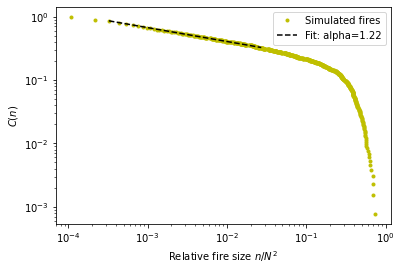

In [4]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.loglog(
    x / N ** 2, 
    y, 
    "y.", 
    label="Simulated fires"
)

fit_x = np.geomspace(lower, upper, 100)
ax.loglog(
    fit_x / N ** 2, 
    np.exp(intercept) * fit_x ** beta, 
    "k--", 
    label=f"Fit: alpha={alpha:.2f}"
)

ax.set(
    xlabel=r"Relative fire size $n/N^2$", 
    ylabel=r"$C(n)$"
)
ax.legend()
plt.show()

<a id="synthetic-power-law"></a>

Let's compare with data generated with a synthetic power-law distribution.

Here we show the implementation of how to generate data with a synthetic power-law distribution with exponent $\alpha$:

In [5]:
xmin = 1.0
r = np.random.random(10000)

synthetic = xmin * r ** (-1 / (alpha - 1))

print(f"Largest synthetic value: {synthetic.max():.3e}")

Largest synthetic value: 1.308e+22


Let's compare cCDF with the data from the synthetic distribution:

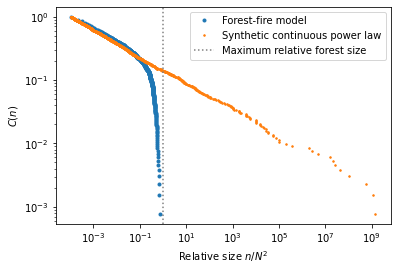

In [6]:
synthetic = ff.synthetic_pareto(
    alpha, 
    xmin=1.0, 
    count=len(sizes)
)
synthetic_x = np.sort(synthetic)
synthetic_c = np.arange(
    len(synthetic_x), 0, -1) / len(synthetic_x)

fig, ax = plt.subplots(figsize=(6, 4))
ax.loglog(x / N**2, y, ".", label="Forest-fire model")
ax.loglog(
    synthetic_x / N**2, 
    synthetic_c, 
    ".", 
    markersize=3, 
    label="Synthetic continuous power law"
)
ax.axvline(
    1, 
    color="gray", 
    ls=":", 
    label="Maximum relative forest size"
)

ax.set(
    xlabel=r"Relative size $n/N^2$", 
    ylabel=r"$C(n)$"
)
ax.legend()
plt.show()

<a id="extrapolation"></a>
**Exercise 3.8:** finite-size extrapolation of the exponent of forest fires model.


In [7]:
forest_sizes = [16, 32, 64, 128]
replicates = 5
alpha_means = []
alpha_std = []

n_steps = 15000
n_discard = 2000

In [8]:
for N_current in forest_sizes:
    estimates = []
    for repeat in range(replicates):
        sample = ff.simulate(
            n=N_current, 
            p=p, 
            f=f, 
            steps=n_steps, 
            burn_in=n_discard
        )
        observed = sample["fire_sizes"]
        fitting_max = max(5, min(100, N_current**2 // 10))
        try:
            estimate, _, _ = ff.exponent_from_ccdf(
                observed, 2, fitting_max)
            estimates.append(estimate)
        except ValueError:
            pass
    alpha_means.append(
        np.mean(estimates) if estimates else np.nan
    )
    alpha_std.append(
        np.std(estimates, ddof=1) if (
            len(estimates) > 1
        )
        else np.nan
    )

Let's plot the fitted exponents vs the inverse of the forest size

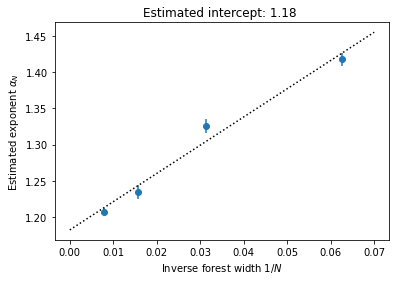

In [9]:
inverse_n = 1 / np.asarray(
    forest_sizes, 
    dtype=float
)
fig, ax = plt.subplots(figsize=(6, 4))
ax.errorbar(
    inverse_n, 
    alpha_means, 
    yerr=alpha_std, 
    fmt="o"
)

# fit attempt:
slope, intercept = np.polyfit(
    inverse_n, alpha_means, 1
)
x = np.arange(0, 0.07, 0.01)
y = slope * x + intercept
ax.plot(x, y, "k:", label="Linear fit")

ax.set(
    xlabel=r"Inverse forest width $1/N$", 
    ylabel=r"Estimated exponent $\alpha_N$",
    title=f"Estimated intercept: {intercept:.2f} "
)
plt.show()

<a id="questions"></a>
## Questions

Here you find the questions:

- [Q9: fitting of cCDF](#q9)
- [Q10: synthetic power law](#q10)
- [Q11: extrapolation of the exponent](#q11)

<a id="q9"></a>
**Q9: fitting of cCDF** 

Refer to [fitting of cCDF](#fit-ccdf)

[Go back to questions](#questions)

Observe the log-log plot of the CCDF versus relative fire size, together with the superimposed linear fit.

a. In the log-log plot, the slope of the fitted line is related to an exponent `beta`. Why is this the case? Isn't the exponent of a linear function always 1?

b. Why do we fit a straight line to the middle part of the curve rather than to the final part (i.e., the sharp drop observed for relative fire sizes greater than `10^(-1)` ? After all, the final part of the CCDF also appears approximately linear. Why not fit that region instead?

c. Would fitting a straight line over the interval between `10^(-2)` and `10^(-1)` give the same value of `beta` as the fit actually performed? Why or why not?

<a id="q10"></a>
**Q10: synthetic power law** 

Refer to [synthetic power law](#synthetic-power-law)

[Go back to questions](#questions)

Consider the lines:
```python
xmin = 1.0
r = np.random.random(10000)

synthetic = xmin * r ** (-1 / (alpha - 1))
```

a. Is `r` composed by values smaller or greater than 1? Explain.

b. Suppose that `alpha = 1.5` and `r = 0.1` <br>
Is `r ** (-1 / (alpha - 1))` smaller or larger than 1? Explain. 

c. Observe the plot comparing the empirical CCDF of fire sizes with the CCDF of a synthetic power-law distribution. Why does the synthetic distribution contain points with x-coordinates greater than 1? Explain.

<a id="q11"></a>
**Q11: Extrapolation of the exponent** 

Refer to [extrapolation](#extrapolation) from finite size.

[Go back to questions](#questions)

The extrapolation of the exponent for the forest fires model is performed using `forest_sizes = [16, 32, 64, 128]`.

a. Suppose you add `N = 96` to the list of the forest sizes and run the simulations under the same conditions as for the other sizes. 
You then calculate the corresponding exponent `alpha`. Indicate a plausible position for this additional data point on the plot and explain your reasoning.


b. Why do we average the estimates of the exponent `alpha` over repeated simulation runs?


c. Suppose you want to simulate the forest-fire model with `N = 5000` (i.e., a forest on a 5000 x 5000 lattice). <br> 
Would the following simulation parameters be appropriate for estimating the corresponding exponent `alpha`?
```python
n_steps = 15000
n_discard = 2000
```
Explain your reasoning.